# Урок 4 — Поворачиваем пятно и разбираемся с ковариационной матрицей

[План курса](../../README_ru.md) · [Предыдущий урок](lesson-03.ipynb) · [English](../en/lesson-04.ipynb) · [Дальше: несколько пятен](lesson-05.ipynb)

В прошлом уроке мы растянули круг в эллипс. Но его длинная сторона всё время лежала вдоль одной из осей. А если нужно нарисовать наклонную ветку или край крыши?

Повернём пятно. В просмотрщике для этого хватит одного ползунка. А рядом появятся четыре числа в квадратных скобках — **ковариационная матрица**. Разберёмся, как они связаны с размером и наклоном и как с их помощью посчитать вес в нужной точке.

Сначала посмотрим на поворот, затем сделаем его обычными умножениями и сложениями. Матрица появится как короткая запись уже знакомых действий.

По пути появятся синус, косинус и умножение матриц. У расчёта будет две записи: через поворот точки назад и через ковариационную матрицу. На одном примере проверим, что они дают одинаковый вес.

## 1. Сначала повернём эллипс

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
from IPython.display import display

course_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "gaussian_math.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from gaussian_math import gaussian2d, covariance_matrix, inverse_covariance
from covariance_demos import (
    covariance_figure, covariance_lab, rotation_figure,
    sample_covariance_figure, inverse_figure,
)
LANG = 'ru'

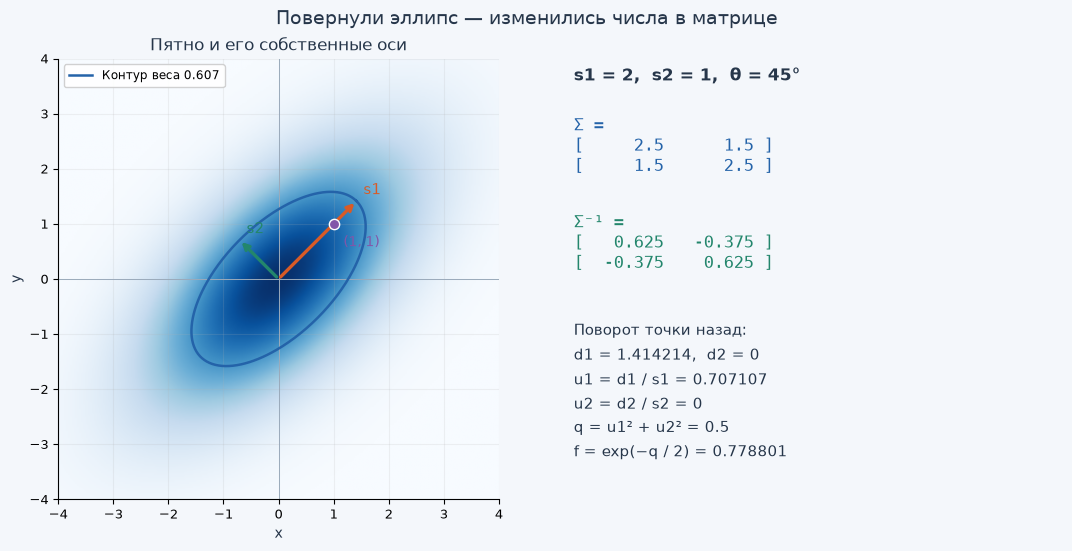

In [2]:
display(covariance_figure(language=LANG))

In [3]:
display(covariance_lab(language=LANG))

В основном примере **масштабы 2 и 1, угол 45°, точка (1, 1)**. Центр в этом уроке закреплён в `(0, 0)`, чтобы перемещение не отвлекало от формы.

1. При переходе от 0° к 45° и затем к −45° длина и толщина пятна сохраняются. Зато вне диагонали матрицы появляются ненулевые числа, а при смене наклона меняется их знак.
2. При угле 45° увеличение первого масштаба растягивает пятно вдоль его наклонной оси, а не строго вправо.
3. В примере «Круг» изменение угла оставляет форму прежней. У круга нет выделенного длинного направления.
4. В основном примере точка `(1, 1)` остаётся неподвижной. При разных наклонах она оказывается то вдоль длинной стороны, то ближе к короткой. Поэтому её вес меняется.
5. В примере «Точка в центре» вес равен 1 независимо от положительных масштабов и угла.

Оранжевая и зелёная стрелки показывают **собственные оси пятна**. Масштабы вдоль них назовём $s_1$ и $s_2$ — «эс один» и «эс два». Индекс снизу просто различает две оси. В исходном примере $s_1=2$, $s_2=1$.

После поворота эти оси уже не совпадают с мировыми $x$ и $y$. Поэтому дальше не будем называть $s_1$ «шириной по x»: это длина масштаба вдоль первой, наклонной оси.

Синяя линия соединяет точки с весом $e^{-1/2}\approx0.607$. Как и в уроке 3, за ней пятно продолжается. Здесь она помогает сравнивать форму.

## 2. Почему в матрице хранятся квадраты размеров

Вспомним осевой эллипс из урока 3. Для точки со смещениями $d_x$ и $d_y$ мы считали:

$$
q=\left(\frac{d_x}{s_1}\right)^2+\left(\frac{d_y}{s_2}\right)^2,
\qquad f=\exp(-q/2).
$$

$d_x=x-\mu_x$ и $d_y=y-\mu_y$ — насколько точка смещена от центра по двум направлениям. Буквы $\mu_x,\mu_y$ обозначают координаты центра. Пока обе равны нулю, так что $d_x=x$, $d_y=y$.

После возведения дробей в квадрат в знаменателях оказываются $s_1^2$ и $s_2^2$. При размерах 2 и 1 это $2\cdot2=4$ и $1\cdot1=1$. Эти квадраты и лягут на диагональ матрицы для неповёрнутого пятна.

Почему их называют **дисперсиями**? Посмотрим на простой набор чисел. Есть четыре координаты: −2, −2, 2, 2. Их среднее:

$$
\bar x=\frac{-2-2+2+2}{4}=0.
$$

Черта над $x$ читается «среднее икс». Вычтем среднее из каждого числа, возведём разницы в квадрат и усредним:

$$
v_x=\frac{(-2-0)^2+(-2-0)^2+(2-0)^2+(2-0)^2}{4}
=\frac{4+4+4+4}{4}=4.
$$

Получилась **дисперсия**: среднее квадратов отклонений от среднего. Она измеряет разброс, но уже в квадратных единицах. Если координаты в сантиметрах, дисперсия 4 см². Чтобы вернуться к сантиметрам, берём корень: $\sqrt4=2$ см. Это **стандартное отклонение**.

Для гауссианы масштаб $s$ устроен так, что $s^2$ соответствует дисперсии нормированного распределения той же формы. Мы по-прежнему рисуем ненормированный вес с вершиной 1; коэффициент для вероятностной плотности нам здесь не нужен.

Четыре числа выше — способ увидеть арифметику разброса. Они не превращаются от этого в гауссиану и не являются её обязательными точками. Размеры нашего пятна задаём сами.

## 3. Ковариация: меняются ли две координаты вместе

Теперь возьмём четыре точки на плоскости:

| Точка | x | y | x² | x·y | y² |
|---|---:|---:|---:|---:|---:|
| A | −2 | −1 | 4 | 2 | 1 |
| B | −2 | 1 | 4 | −2 | 1 |
| C | 2 | −1 | 4 | −2 | 1 |
| D | 2 | 1 | 4 | 2 | 1 |
| Среднее | 0 | 0 | 4 | 0 | 1 |

Средние координаты равны нулю. Поэтому отклонения от среднего совпадают с самими $x$ и $y$.

Квадраты в столбцах $x^2$ и $y^2$ дают дисперсии 4 и 1. А столбец $x\cdot y$ отвечает на другой вопрос: **совпадают ли знаки отклонений двух координат?** Если обе положительные или обе отрицательные, произведение положительно. Если знаки разные — отрицательно.

Среднее этих произведений называют **ковариацией**:

$$
b=\frac{2-2-2+2}{4}=0.
$$

Положительные и отрицательные вклады сократились. У этого набора нет предпочтения ни наклону «вправо-вверх», ни наклону «вправо-вниз».

Если центр набора не в нуле, сначала вычитаем средние. Общая запись:

$$
b=\frac1N\sum_{i=1}^{N}(x_i-\bar x)(y_i-\bar y).
$$

Разберём запись: $N$ — число точек; $i$ — номер текущей точки; $x_i,y_i$ — две её координаты; $\sum$ («сигма») обозначает сумму результатов для всех номеров от 1 до N. Для каждой точки вычитаем средние, умножаем два отклонения, складываем произведения и делим на количество точек.

Здесь мы описываем **весь заданный набор** и делим на $N=4$. В статистике при оценке неизвестной ковариации по случайной выборке часто используют $N-1$. Это другая задача; переключаться между двумя делителями посреди примера нельзя.

Ковариация тоже имеет единицы см², если обе координаты в сантиметрах. Это не угол в градусах. Наклон связан с ней вместе с двумя дисперсиями: одно число $b$ само по себе не определяет весь эллипс.

## 4. Четыре числа вместо трёх длинных подписей

Сложим найденные числа в таблицу из двух строк и двух столбцов:

$$
\Sigma=
\begin{bmatrix}
v_x & b\\
b & v_y
\end{bmatrix}
=\begin{bmatrix}4&0\\0&1\end{bmatrix}.
$$

Большая $\Sigma$ читается «сигма». Здесь это имя всей матрицы, а не маленькая $\sigma$ из урока 2. Матрица — прямоугольная таблица чисел, для которой дальше зададим правила действий.

- Верхняя левая ячейка — дисперсия по мировой оси $x$.
- Нижняя правая — дисперсия по мировой оси $y$.
- Две другие — ковариация. Они одинаковы, потому что порядок множителей $x\cdot y$ и $y\cdot x$ не меняет произведение.

Линия от верхней левой ячейки к нижней правой называется **главной диагональю**. Матрица с одинаковыми числами по обе стороны от неё называется **симметричной**.

У нашего неповёрнутого пятна:

$$
D=\begin{bmatrix}s_1^2&0\\0&s_2^2\end{bmatrix}
=\begin{bmatrix}4&0\\0&1\end{bmatrix}.
$$

Имя $D$ оставим для матрицы в собственных осях пятна. В записи $\mathrm{diag}(4,1)$ `diag` обозначает матрицу с числами 4 и 1 на диагонали и нулями в остальных ячейках.

Пока оси пятна совпадают с $x,y$, матрицы $D$ и $\Sigma$ одинаковы. После поворота $D$ сохранит прежние 4 и 1, а запись формы в мировых координатах $\Sigma$ изменится.

## 5. Поворот без готовой матрицы: две проекции стрелки

Нарисуем стрелку длины 1, сначала направленную вправо. Её конец находится в `(1, 0)`. Повернём стрелку против часовой стрелки на угол $\theta$ — «тета».

Полный оборот — 360°, четверть оборота — 90°. Угол 45° находится посередине между направлением вправо и направлением вверх.

После поворота у конца стрелки две координаты:

$$
(\cos\theta,\ \sin\theta).
$$

**Косинус** — горизонтальная координата конца единичной стрелки, **синус** — вертикальная. Это подписанные проекции: слева горизонтальная координата отрицательна, ниже нуля вертикальная тоже отрицательна.

| Угол | cos θ | sin θ | Куда смотрит первая ось |
|---|---:|---:|---|
| 0° | 1 | 0 | Вправо |
| 90° | 0 | 1 | Вверх |
| 180° | −1 | 0 | Влево |
| −90° | 0 | −1 | Вниз |

При 45° две проекции одинаковы. Для прямоугольного треугольника квадрат длины наклонной стороны равен сумме квадратов двух прямых сторон. Поэтому для стрелки длины 1: $c^2+c^2=1$, то есть $2c^2=1$, $c^2=1/2$, $c=1/\sqrt2\approx0.707107$. Берём положительный корень: стрелка направлена вправо-вверх. Значит, $\cos45°=\sin45°=1/\sqrt2$.

Дальше для краткости напишем $c=\cos\theta$, $s=\sin\theta$. Здесь $s$ **без индекса** — синус; размеры пятна остаются $s_1,s_2$.

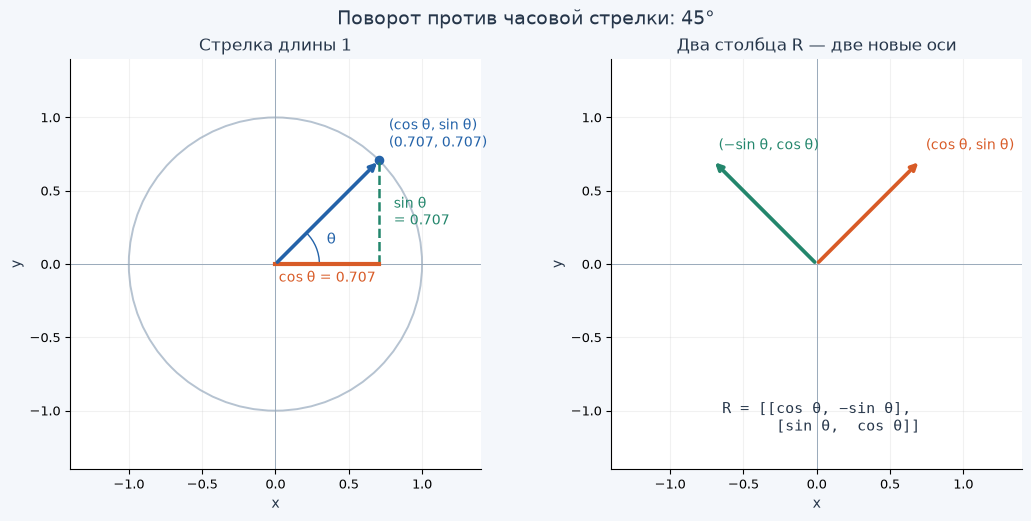

In [4]:
display(rotation_figure(angle_deg=45, language=LANG))

Вторая ось должна быть перпендикулярна первой. Если первая направлена в $(c,s)$, то вторая — в $(-s,c)$. При 45° это `(-0.707107, 0.707107)`: влево-вверх. Длины обеих стрелок равны 1.

Пусть точка лежит на $a$ единиц вдоль первой оси и на $b$ единиц вдоль второй. Буквы $a,b$ здесь обозначают две координаты точки в системе пятна; букву $b$ для ковариации пока отложим. Сложим два перемещения:

$$
\begin{aligned}
x&=ca-sb,\\
y&=sa+cb.
\end{aligned}
$$

Например, $(a,b)=(2,0)$ при 45° даёт $x=0.707107\cdot2-0.707107\cdot0\approx1.414214$, $y=0.707107\cdot2+0.707107\cdot0\approx1.414214$.

Сами числа 2 и 0 не изменились как координаты вдоль собственных осей. Мы пересчитали, где находится эта же точка в мировой системе.

## 6. Записываем тот же поворот матрицей

Поместим коэффициенты двух действий в таблицу:

$$
R=\begin{bmatrix}c&-s\\s&c\end{bmatrix},
\qquad
\begin{bmatrix}x\\y\end{bmatrix}
=R\begin{bmatrix}a\\b\end{bmatrix}.
$$

$R$ — имя матрицы поворота. Запись двух чисел столбиком — **вектор-столбец**. Здесь он просто хранит две координаты.

Умножение матрицы на столбец делается **строка на столбец**. Для первой выходной координаты умножаем каждое число первой строки на соответствующее число столбца и складываем: $c\cdot a+(-s)\cdot b$. Для второй берём вторую строку: $s\cdot a+c\cdot b$. Никакого нового геометрического действия по сравнению с предыдущим разделом здесь нет.

Столбцы самой $R$ тоже понятны: первый говорит, куда переместилась единичная стрелка `(1,0)`, второй — куда переместилась `(0,1)`.

В Python оператор `@` выполняет такое матричное умножение. Обычный `*` у массивов NumPy умножает элементы попарно, поэтому заменять им `@` нельзя.

Функции `math.sin` и `math.cos` принимают угол **в радианах**. Один радиан — угол, которому на окружности радиуса 1 соответствует дуга длины 1. Полный оборот имеет длину дуги $2\pi$, поэтому 360° — это $2\pi$ радиан. Значит, 180° — $\pi$, а 45° — $\pi/4\approx0.785398$. Число $\pi\approx3.141593$ — отношение длины окружности к её диаметру. `math.radians` сделает перевод за нас.

In [5]:
theta_deg = 45.0
theta_rad = math.radians(theta_deg)
c = math.cos(theta_rad)
s = math.sin(theta_rad)
R = np.array([[c, -s], [s, c]])
local_point = np.array([2.0, 0.0])
world_point = R @ local_point
print("angle in radians =", round(theta_rad, 6))
print("cos, sin =", round(c, 6), round(s, 6))
print("R =\n", np.round(R, 6))
print("world point =", np.round(world_point, 6))

angle in radians = 0.785398
cos, sin = 0.707107 0.707107
R =
 [[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
world point = [1.414214 1.414214]


## 7. Чтобы посчитать вес, повернём точку назад

Мы уже умеем превращать координаты вдоль осей пятна в мировые. Но в просмотрщике задаём мировую точку. Чтобы воспользоваться формулой урока 3, нужно узнать её смещения **вдоль собственных осей** эллипса.

Поэтому сначала вычитаем центр, затем поворачиваем полученное смещение на **минус тот же угол**. Для поворота это делает транспонированная матрица:

$$
R^T=\begin{bmatrix}c&s\\-s&c\end{bmatrix}.
$$

Верхняя буква $T$ читается «транспонирование», а не степень. Строки становятся столбцами: верхняя правая и нижняя левая ячейки меняются местами. Именно у матрицы поворота такое переставление даёт обратный поворот; у произвольной матрицы транспонирование не заменяет обращение.

Обозначим мировое смещение столбцом $d$, а две координаты после обратного поворота — $d_1,d_2$:

$$
d=\begin{bmatrix}d_x\\d_y\end{bmatrix},
\qquad
\begin{bmatrix}d_1\\d_2\end{bmatrix}
=R^Td
=\begin{bmatrix}cd_x+sd_y\\-sd_x+cd_y\end{bmatrix}.
$$

Посчитаем для `(1,1)`, центра `(0,0)` и угла 45°. Используем точные $c=s=1/\sqrt2$, а в пояснениях округлим:

$$
\begin{aligned}
d_x&=1-0=1,\qquad d_y=1-0=1,\\
d_1&=\frac1{\sqrt2}\cdot1+\frac1{\sqrt2}\cdot1=\sqrt2\approx1.414214,\\
d_2&=-\frac1{\sqrt2}\cdot1+\frac1{\sqrt2}\cdot1=0.
\end{aligned}
$$

Точка лежит целиком вдоль первой, длинной оси. Делим на её масштаб 2, а вторую координату — на масштаб 1:

$$
\begin{aligned}
u_1&=d_1/s_1=\sqrt2/2=1/\sqrt2,\\
u_2&=d_2/s_2=0/1=0,\\
q&=u_1^2+u_2^2=1/2+0=0.5,\\
f&=\exp(-0.5/2)=\exp(-0.25)\approx0.778801.
\end{aligned}
$$

Два первых деления измерили смещения в единицах соответствующей ширины. Квадраты убрали знаки, сумма объединила два направления, а экспонента превратила расстояние в вес. Все действия после поворота уже знакомы.

Для проверки обратного поворота перемножим $R^TR$. Первая диагональная ячейка равна $c^2+s^2=1$, вторая тоже 1; вне диагонали получаем $-cs+sc=0$. Значит, поворот и поворот назад действительно возвращают исходные координаты.

In [6]:
d = np.array([1.0, 1.0])
local = R.T @ d
u = local / np.array([2.0, 1.0])
q_local = u[0] * u[0] + u[1] * u[1]
weight_local = math.exp(-q_local / 2)
print("R.T @ R =\n", np.round(R.T @ R, 6))
print("local offsets =", np.round(local, 6))
print("scaled offsets =", np.round(u, 6))
print("q =", round(q_local, 6))
print("weight =", round(weight_local, 6))

R.T @ R =
 [[ 1. -0.]
 [-0.  1.]]
local offsets = [1.414214 0.      ]
scaled offsets = [0.707107 0.      ]
q = 0.5
weight = 0.778801


## 8. Как поворот меняет ковариационную матрицу

Вернёмся к четырём числам формы. Нам нужна матрица в мировых координатах, хотя размеры $s_1,s_2$ заданы вдоль собственных осей пятна.

Сначала посмотрим, откуда появляется правило преобразования. Столбец смещения $d$ можно умножить на его транспонированную строку:

$$
\begin{bmatrix}d_x\\d_y\end{bmatrix}
\begin{bmatrix}d_x&d_y\end{bmatrix}
=\begin{bmatrix}d_x^2&d_xd_y\\d_yd_x&d_y^2\end{bmatrix}.
$$

Умножение здесь снова идёт строка на столбец. В каждой ячейке только одна пара чисел: верхняя левая — $d_x\cdot d_x$, верхняя правая — $d_x\cdot d_y$ и так далее. Получились именно те квадраты и произведения, которые мы усредняли для дисперсий и ковариации.

После поворота каждое смещение становится $Rd$. Транспонированная строка при этом становится $d^TR^T$: порядок двух множителей меняется. Поэтому таблица произведений после поворота равна $R(dd^T)R^T$. Если усреднить такие таблицы, одинаковую для всех точек $R$ можно оставить снаружи. Так получаем правило:

$$
\Sigma=RDR^T.
$$

Это правило преобразования ковариации при повороте. Для гауссианы оно описывает ту же форму в другой системе осей. Четыре угловые точки помогают увидеть арифметику, но вместо гауссианы мы ими ничего не подменяем.

Теперь раскроем оба умножения. Сначала $R$ на $D$. Для каждой ячейки берём строку левой матрицы и столбец правой:

$$
RD=
\begin{bmatrix}c&-s\\s&c\end{bmatrix}
\begin{bmatrix}s_1^2&0\\0&s_2^2\end{bmatrix}
=\begin{bmatrix}cs_1^2&-ss_2^2\\ss_1^2&cs_2^2\end{bmatrix}.
$$

Например, верхняя левая ячейка: $c\cdot s_1^2+(-s)\cdot0=cs_1^2$. Верхняя правая: $c\cdot0+(-s)\cdot s_2^2=-ss_2^2$. Нули убрали по одному слагаемому. Нижняя строка считается так же.

Осталось умножить полученную таблицу на $R^T$. Все четыре ячейки:

$$
\begin{aligned}
\Sigma_{11}&=(cs_1^2)c+(-ss_2^2)(-s)=c^2s_1^2+s^2s_2^2,\\
\Sigma_{12}&=(cs_1^2)s+(-ss_2^2)c=cs(s_1^2-s_2^2),\\
\Sigma_{21}&=(ss_1^2)c+(cs_2^2)(-s)=cs(s_1^2-s_2^2),\\
\Sigma_{22}&=(ss_1^2)s+(cs_2^2)c=s^2s_1^2+c^2s_2^2.
\end{aligned}
$$

Индексы `11`, `12`, `21`, `22` читаются как «номер строки, номер столбца», начиная с 1. Например, $\Sigma_{12}$ — первая строка, второй столбец. Две ячейки вне диагонали совпали, как и должно быть у ковариационной матрицы.

В исходном примере $s_1^2=4$, $s_2^2=1$, а при 45° $c^2=s^2=cs=1/2$. Подставим:

$$
\begin{aligned}
\Sigma_{11}&=(1/2)\cdot4+(1/2)\cdot1=2+0.5=2.5,\\
\Sigma_{12}&=(1/2)(4-1)=1.5,\\
\Sigma_{21}&=1.5,\\
\Sigma_{22}&=(1/2)\cdot4+(1/2)\cdot1=2.5.
\end{aligned}
$$

Получилась матрица, которую мы видели в начале:

$$
\Sigma=\begin{bmatrix}2.5&1.5\\1.5&2.5\end{bmatrix}.
$$

Числа 2.5 на диагонали означают одинаковые дисперсии **по мировым x и y**. Но пятно не стало кругом: положительные 1.5 связывают эти направления и сохраняют наклонную вытянутую форму. Его собственные масштабы всё ещё 2 и 1. Мировые стандартные отклонения теперь равны $\sqrt{2.5}\approx1.581139$.

In [7]:
s1, s2 = 2.0, 1.0
D = np.array([[s1 * s1, 0.0], [0.0, s2 * s2]])
RD = R @ D
Sigma = RD @ R.T
print("D =\n", D)
print("R @ D =\n", np.round(RD, 6))
print("Sigma =\n", np.round(Sigma, 6))

D =
 [[4. 0.]
 [0. 1.]]
R @ D =
 [[ 2.828427 -0.707107]
 [ 2.828427  0.707107]]
Sigma =
 [[2.5 1.5]
 [1.5 2.5]]


## 9. Проверим матрицу на тех же четырёх точках

Повернём наш прямоугольный набор. У точки A были координаты `(−2,−1)`. После поворота на 45°:

$$
\begin{aligned}
x_A&=-2/\sqrt2+1/\sqrt2=-1/\sqrt2\approx-0.707107,\\
y_A&=-2/\sqrt2-1/\sqrt2=-3/\sqrt2\approx-2.121320.
\end{aligned}
$$

Её квадрат $x_A^2=1/2=0.5$, квадрат $y_A^2=9/2=4.5$, а произведение $x_Ay_A=3/2=1.5$. Две отрицательные координаты дали положительный вклад в ковариацию.

На рисунке посчитаны и остальные точки. Значения для показа округлены; в расчёте используются исходные числа.

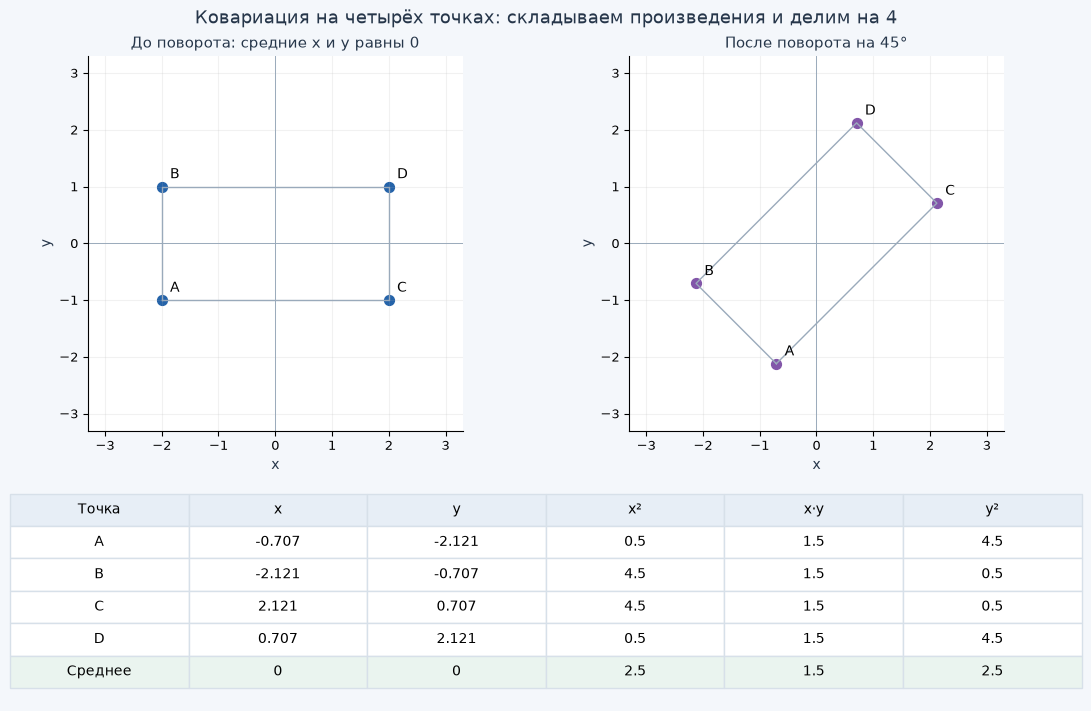

In [8]:
display(sample_covariance_figure(angle_deg=45, language=LANG))

Средние координаты по-прежнему равны нулю. Считаем средние квадратов и произведений:

$$
\begin{aligned}
v_x&=(0.5+4.5+4.5+0.5)/4=10/4=2.5,\\
b&=(1.5+1.5+1.5+1.5)/4=6/4=1.5,\\
v_y&=(4.5+0.5+0.5+4.5)/4=10/4=2.5.
\end{aligned}
$$

Те же числа, что и в $RDR^T$. Если повернуть исходный прямоугольник на −45°, диагональные ячейки останутся 2.5, а две другие станут −1.5. При одинаковых дисперсиях знак ковариации отличит два направления наклона.

Нулевая ковариация не означает, что две величины вообще никак не связаны: она проверяет именно среднее произведение отклонений. Здесь нам важна геометрия гауссианы, для которой ковариационная матрица вместе с центром задаёт форму веса.

## 10. Зачем нужна обратная матрица

Обычный квадрат расстояния увеличивается, когда мы отходим от центра. Но одинаковый шаг вдоль длинной и короткой сторон должен давать разный вес. В уроке 3 мы решали это делением на масштабы.

В матрице формы хранятся **квадраты** масштабов. Поэтому в расчёте квадрата расстояния нам нужны их обратные значения: вместо 4 — $1/4$, вместо 1 — $1/1$. Для повёрнутого пятна этот шаг делает **обратная матрица** $\Sigma^{-1}$ — «сигма в минус первой степени».

Обращение матрицы не сводится к замене каждой ячейки её обратным числом. У него другое определение: при умножении на исходную она должна дать **единичную матрицу**:

$$
I=\begin{bmatrix}1&0\\0&1\end{bmatrix},
\qquad
\Sigma\Sigma^{-1}=I.
$$

Название понятно на столбце: первая строка $I$ даёт $1\cdot x+0\cdot y=x$, вторая — $0\cdot x+1\cdot y=y$. Такой множитель ничего не меняет.

Для общей симметричной таблицы временно назовём её три разных числа $A,B,C$:

$$
\Sigma=\begin{bmatrix}A&B\\B&C\end{bmatrix}.
$$

Здесь $A$ — верхняя левая ячейка, $C$ — нижняя правая, $B$ — обе ячейки вне диагонали. Это не масштабы $s_1,s_2$. У нашего примера $A=C=2.5$, $B=1.5$.

Сначала вычислим **определитель** (его также называют детерминантом):

$$
\Delta=AC-B^2.
$$

$\Delta$ читается «дельта». Для таблицы 2×2 правило такое: произведение чисел главной диагонали минус произведение чисел другой диагонали. В симметричной матрице второе произведение — $B\cdot B=B^2$.

Почему именно это число появляется при обращении? Поменяем диагональные ячейки местами, а двум другим поменяем знак, затем перемножим:

$$
\begin{aligned}
\begin{bmatrix}A&B\\B&C\end{bmatrix}
\begin{bmatrix}C&-B\\-B&A\end{bmatrix}
&=\begin{bmatrix}AC-B^2&-AB+BA\\BC-CB&-B^2+CA\end{bmatrix}\\
&=\begin{bmatrix}\Delta&0\\0&\Delta\end{bmatrix}.
\end{aligned}
$$

Каждая ячейка раскрыта как строка на столбец. Два недиагональных результата сократились до нуля. Если $\Delta\ne0$, осталось разделить каждую ячейку второй матрицы на $\Delta$ — и на диагонали результата появятся единицы:

$$
\Sigma^{-1}=\frac1\Delta
\begin{bmatrix}C&-B\\-B&A\end{bmatrix}.
$$

Это и есть формула обращения. Она не отдельный трюк для запоминания: мы только что проверили, как она отменяет исходное умножение.

## 11. Полный расчёт обратной матрицы для нашего пятна

Подставим числа:

$$
\Delta=2.5\cdot2.5-1.5\cdot1.5=6.25-2.25=4.
$$

Теперь меняем диагональные ячейки местами, ставим минусы у двух других и делим всё на 4:

$$
\begin{aligned}
\Sigma^{-1}
&=\frac14\begin{bmatrix}2.5&-1.5\\-1.5&2.5\end{bmatrix}\\
&=\begin{bmatrix}2.5/4&-1.5/4\\-1.5/4&2.5/4\end{bmatrix}\\
&=\begin{bmatrix}0.625&-0.375\\-0.375&0.625\end{bmatrix}.
\end{aligned}
$$

Проверим две ячейки произведения $\Sigma\Sigma^{-1}$:

$$
\begin{aligned}
(\Sigma\Sigma^{-1})_{11}
&=2.5\cdot0.625+1.5\cdot(-0.375)\\
&=1.5625-0.5625=1,\\
(\Sigma\Sigma^{-1})_{12}
&=2.5\cdot(-0.375)+1.5\cdot0.625\\
&=-0.9375+0.9375=0.
\end{aligned}
$$

Нижняя строка даёт 0 и 1. Мы действительно получили $I$.

Если координаты измеряются в сантиметрах, элементы $\Sigma$ имеют единицы см². В определителе перемножаются две такие величины: единицы см⁴. Поэтому деление ячеек на определитель даёт см² / см⁴ = 1/см² для $\Sigma^{-1}$. Дальше эти единицы сократятся с двумя смещениями.

В коде индексы начинаются с **0**: математическая ячейка $\Sigma_{11}$ записывается как `Sigma[0, 0]`. Первая цифра выбирает строку, вторая — столбец.

In [9]:
A = Sigma[0, 0]
B = Sigma[0, 1]
C = Sigma[1, 1]
determinant = A * C - B * B
inverse_manual = np.array([[C, -B], [-B, A]]) / determinant
print("A*C - B*B =", round(determinant, 6))
print("inverse =\n", np.round(inverse_manual, 6))
print("Sigma @ inverse =\n", np.round(Sigma @ inverse_manual, 6))

A*C - B*B = 4.0
inverse =
 [[ 0.625 -0.375]
 [-0.375  0.625]]
Sigma @ inverse =
 [[1. 0.]
 [0. 1.]]


## 12. Как прочитать dᵀΣ⁻¹d и получить одно число

Теперь мы готовы к компактной формуле гауссианы:

$$
f(x,y)=\exp\left(-\frac12d^T\Sigma^{-1}d\right),
\qquad
d=\begin{bmatrix}x-\mu_x\\y-\mu_y\end{bmatrix}.
$$

Пройдём её **изнутри наружу**:

1. Вычитаем центр и получаем столбец $d$ с двумя смещениями.
2. Умножаем $\Sigma^{-1}$ на $d$ и получаем новый столбец из двух чисел.
3. Слева умножаем его на строку $d^T$: складываем два произведения и получаем одно число $q$.
4. Делим $q$ на 2, ставим минус и вычисляем экспоненту.

Вся запись $d^T\Sigma^{-1}d$ заменяет знакомую сумму квадратов нормированных смещений. Её называют **квадратичной формой**: смещение участвует в умножении дважды. Слово описывает устройство выражения, а не добавляет ещё одну операцию.

Для точки `(1,1)` первое смещение $d_x=1$, второе $d_y=1$. Сначала умножим матрицу на столбец:

$$
v=\Sigma^{-1}d
=\begin{bmatrix}0.625&-0.375\\-0.375&0.625\end{bmatrix}
\begin{bmatrix}1\\1\end{bmatrix}
=\begin{bmatrix}0.625-0.375\\-0.375+0.625\end{bmatrix}
=\begin{bmatrix}0.25\\0.25\end{bmatrix}.
$$

$v$ — временное имя этого столбца. Теперь берём исходное смещение строкой и умножаем на него:

$$
q=d^Tv
=\begin{bmatrix}1&1\end{bmatrix}\begin{bmatrix}0.25\\0.25\end{bmatrix}
=1\cdot0.25+1\cdot0.25=0.5.
$$

Остались последние два действия:

$$
-q/2=-0.5/2=-0.25,
\qquad f(1,1)=\exp(-0.25)\approx0.778801.
$$

Получился тот же вес, что и через обратный поворот точки. В матричной записи мы просто собрали работу с наклоном и масштабами в одну таблицу.

С единицами тоже всё сошлось: смещение в см, обратная матрица в 1/см², ещё одно смещение в см. Получаем см × 1/см² × см = 1. Значит, $q$ безразмерен, как и показатель экспоненты.

In [10]:
offset = np.array([1.0, 1.0])
v = inverse_manual @ offset
q_matrix = offset @ v
weight_matrix = math.exp(-q_matrix / 2)
weight_direct = gaussian2d(1, 1, sx=2, sy=1, angle_deg=45)
print("inverse @ offset =", np.round(v, 6))
print("offset @ v =", round(float(q_matrix), 6))
print("matrix weight =", round(weight_matrix, 6))
print("local-coordinate weight =", round(weight_local, 6))
print("demo weight =", round(float(weight_direct), 6))

inverse @ offset = [0.25 0.25]
offset @ v = 0.5
matrix weight = 0.778801
local-coordinate weight = 0.778801
demo weight = 0.778801


Следующий рисунок показывает тот же расчёт геометрически. Мы последовательно поворачиваем координаты назад, затем делим их на масштабы. Контур веса 0.607 превращается в круг радиуса 1. В последней системе обычная сумма квадратов координат уже даёт нужное $q$.

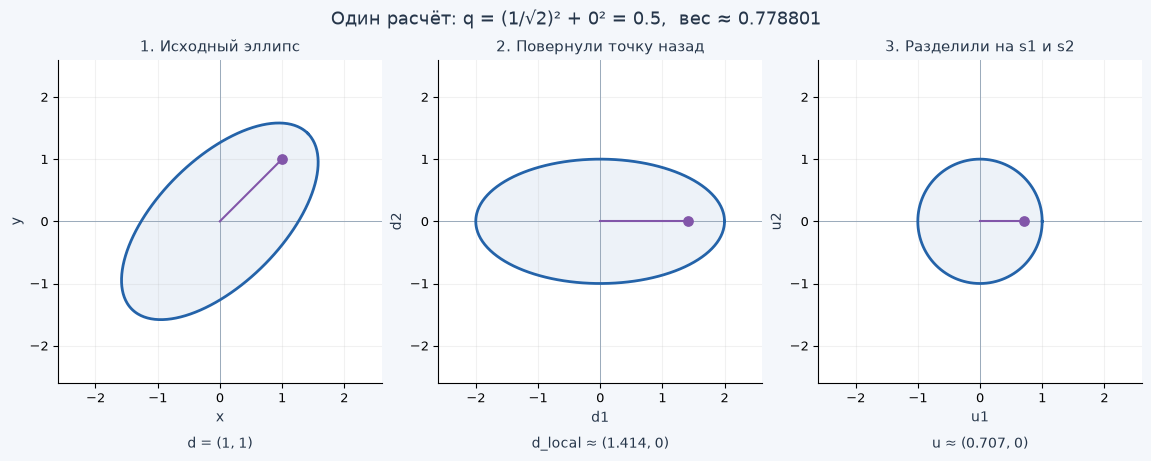

In [11]:
display(inverse_figure(language=LANG))

## 13. Какие числа нельзя записывать в матрицу формы

Значение $q$ должно быть положительным при любом ненулевом смещении. Тогда в центре вес 1, а при удалении он уменьшается. Матрицу с таким свойством называют **положительно определённой**. В нашей гауссиане положительно определены и $\Sigma$, и её обратная матрица.

Для симметричной матрицы 2×2 это проверяется двумя условиями:

$$
A>0,\qquad \Delta=AC-B^2>0.
$$

Первое требует положительного разброса по первой мировой оси. Второе запрещает ковариации стать настолько большой, что одна из независимых ширин исчезнет или квадрат расстояния станет отрицательным.

<details>
<summary>Почему этих двух условий достаточно: раскрываем квадраты</summary>

Из формулы обратной матрицы для произвольного смещения получаем:

$$
q=\frac{Cd_x^2-2Bd_xd_y+Ad_y^2}{\Delta}.
$$

Перекрёстное произведение появляется два раза: один раз из верхней строки, один — из нижней. Поэтому перед ним коэффициент 2.

Тот же результат можно записать как сумму двух квадратов:

$$
q=\frac{d_x^2}{A}+\frac{A}{\Delta}\left(d_y-\frac{B}{A}d_x\right)^2.
$$

Проверим: раскрытие второго квадрата даёт $Ad_y^2/\Delta-2Bd_xd_y/\Delta+B^2d_x^2/(A\Delta)$. Прибавляем $d_x^2/A$; общий коэффициент перед $d_x^2$ равен $(\Delta+B^2)/(A\Delta)=AC/(A\Delta)=C/\Delta$. Получилась исходная формула.

При $A>0$ и $\Delta>0$ оба коэффициента перед квадратами положительны. Если $d_x\ne0$, положительно первое слагаемое. Если $d_x=0$, но $d_y\ne0$, положительно второе. Поэтому любое ненулевое смещение даёт $q>0$.

</details>

Посмотрим на три случая:

| Матрица | Определитель | Что произошло |
|---|---:|---|
| `[[2.5, 1.5], [1.5, 2.5]]` | 4 | Две положительные ширины, можно считать вес |
| `[[1, 1], [1, 1]]` | 0 | Одна ширина схлопнулась; обычной обратной матрицы нет |
| `[[1, 2], [2, 1]]` | −3 | Матрица обратима, но не задаёт нужную гауссиану |

Во втором случае ковариация может корректно описывать точки, лежащие на одной линии. Но для нашей невырожденной двумерной гауссианы нужна положительная ширина в каждом направлении, иначе формула с обычной обратной матрицей неприменима.

В третьем случае обратная матрица равна `[[-1/3, 2/3], [2/3, -1/3]]`. Для смещения `(1,−1)` она даёт столбец `(−1,1)`, затем $q=1\cdot(-1)+(-1)\cdot1=-2$. Получаем $\exp(-(-2)/2)=e^1\approx2.71828$ — вес больше вершины. Знак определителя предупредил нас именно о таком нарушении.

Поэтому в ползунках мы задаём положительные $s_1,s_2$ и угол, а матрицу собираем из них. Так проще сохранить допустимую форму, чем независимо крутить её ячейки.

Следующая ячейка ловит ошибку через `try/except`: неправильные примеры не прерывают весь ноутбук. Это проверка ввода, а не попытка нарисовать гауссиану с нулевой шириной.

In [12]:
examples = [
    np.array([[2.5, 1.5], [1.5, 2.5]]),
    np.array([[1.0, 1.0], [1.0, 1.0]]),
    np.array([[1.0, 2.0], [2.0, 1.0]]),
]
for matrix in examples:
    print(matrix.tolist())
    try:
        valid_inverse = inverse_covariance(matrix)
        print("Можно считать вес" if LANG == "ru" else "Valid for the weight calculation")
        print(np.round(valid_inverse, 6))
    except ValueError:
        print("Матрица формы не подходит" if LANG == "ru" else "Not a valid shape matrix")

[[2.5, 1.5], [1.5, 2.5]]
Можно считать вес
[[ 0.625 -0.375]
 [-0.375  0.625]]
[[1.0, 1.0], [1.0, 1.0]]
Матрица формы не подходит
[[1.0, 2.0], [2.0, 1.0]]
Матрица формы не подходит


## 14. Вернёмся к ползункам

Теперь у каждого числа в таблице рядом с эллипсом есть геометрический смысл. В ней видны квадраты разброса по мировым направлениям и связь этих направлений. Обратная матрица показывает, как учитывать эту форму при расчёте веса.

У трёх следующих опытов одна отправная точка: основной пример, $s_1=2$, $s_2=1$, угол 45°, точка `(1,1)`. В каждом меняется только параметр из левого столбца. Что произойдёт с матрицей и весом?

| Изменение | Ожидаемый результат |
|---|---|
| Угол 45° → 0° | Какая матрица получится и почему вес уменьшится? |
| Угол 45° → −45° | Какие ячейки сменят знак? Вдоль какой оси окажется точка? |
| Оба масштаба равны 2 | Что останется от зависимости матрицы и веса от угла? |

<details>
<summary>Числа для сравнения</summary>

**0°.** Матрица $\Sigma=\mathrm{diag}(4,1)$, обратная — $\mathrm{diag}(1/4,1)$. Для точки `(1,1)` получаем $q=1^2/4+1^2/1=0.25+1=1.25$, показатель $-1.25/2=-0.625$, вес $\exp(-0.625)\approx0.535261$.

**−45°.** Матрица `[[2.5,−1.5],[−1.5,2.5]]`. При обратном повороте $d_1=(1-1)/\sqrt2=0$, $d_2=(1+1)/\sqrt2=\sqrt2$. Деление на масштабы даёт $u_1=0/2=0$, $u_2=\sqrt2/1=\sqrt2$. Поэтому $q=0+2=2$, показатель −1, вес $e^{-1}\approx0.367879$. Та же мировая точка теперь лежит вдоль короткой стороны.

**Оба масштаба 2.** В диагональных ячейках $4c^2+4s^2=4(c^2+s^2)=4$. Вне диагонали $cs(4-4)=0$. Получается $\Sigma=4I$ при любом угле. Для `(1,1)` сумма $q=1/4+1/4=0.5$, вес около 0.778801. Совпадение веса с исходным примером в одной точке не означает совпадения всей формы: здесь круг, а в исходном примере эллипс.

</details>

Поворот на 180° тоже оставляет форму пятна прежней. Это видно при сравнении 45° и −135°. Обе собственные стрелки развернутся, но квадраты двух локальных координат сохранятся.

Очень маленький положительный масштаб допустим математически, но делает обратные значения очень большими. Поэтому вычисления становятся чувствительнее к округлению. В ползунках нижняя граница 0.25 выбрана для удобного опыта; это не универсальная нижняя граница гауссиан.

## 15. Несколько задач с полным разбором

### Задача 1. Почему равная диагональ ещё не даёт круг?

У матриц `[[2.5,1.5],[1.5,2.5]]` и `[[2.5,0],[0,2.5]]` одинаковая диагональ. Как будут различаться пятна?

<details>
<summary>Разбор</summary>

У первой матрицы собственные масштабы 2 и 1 при повороте 45° — это наш эллипс. Во второй нет смешивания направлений, а два масштаба одинаковы: $\sqrt{2.5}$ и $\sqrt{2.5}$. Поэтому это круг.

Посмотрим на `(1,1)`. Для первой матрицы уже получили $q=0.5$ и вес около 0.778801. У второй обратная диагональ $1/2.5=0.4$, поэтому $q=0.4\cdot1^2+0.4\cdot1^2=0.8$, показатель −0.4, вес $e^{-0.4}\approx0.670320$. Различие появилось даже при одинаковых диагональных ячейках.

</details>

### Задача 2. Два способа посчитать вес в точке `(2,0)`

Даны основная матрица `[[2.5,1.5],[1.5,2.5]]` и центр `(0,0)`. Какой вес получится через обратную матрицу, а какой — через обратный поворот и деление на масштабы?

<details>
<summary>Разбор</summary>

Через матрицу: $v_x=0.625\cdot2-0.375\cdot0=1.25$, $v_y=-0.375\cdot2+0.625\cdot0=-0.75$. Далее $q=2\cdot1.25+0\cdot(-0.75)=2.5$. Показатель −1.25, вес $e^{-1.25}\approx0.286505$.

Через поворот: $d_1=2/\sqrt2=\sqrt2$, $d_2=-2/\sqrt2=-\sqrt2$. Делим: $u_1=\sqrt2/2=1/\sqrt2$, $u_2=-\sqrt2/1=-\sqrt2$. Квадраты: $u_1^2=1/2$, $u_2^2=2$. Сумма $q=0.5+2=2.5$ — тот же результат. Отрицательная вторая координата не дала отрицательного веса.

</details>

### Задача 3. Почему нельзя просто обратить каждую ячейку?

К матрице `[[4,0],[0,1]]` применяем правило «один разделить на каждую ячейку». Где оно сломается и как выглядит настоящая обратная матрица?

<details>
<summary>Разбор</summary>

Вне диагонали пришлось бы делить на ноль. Но сама матрица вполне допустима: определитель $4\cdot1-0\cdot0=4$. По формуле обращения получаем $\frac14\begin{bmatrix}1&0\\0&4\end{bmatrix}=\begin{bmatrix}0.25&0\\0&1\end{bmatrix}$. Обращаются два ненулевых диагональных масштаба, а нули остаются нулями. Для непустых ячеек вне диагонали работает общая формула, а не попарные обратные числа.

</details>

### Задача 4. Переводим сантиметры в метры

Точка `(1,1)` см и масштабы 2 см и 1 см заданы при 45°. Если все координаты и масштабы перевести в метры, должен ли измениться вес?

<details>
<summary>Разбор</summary>

Каждая длина уменьшится в записи в 100 раз: точка `(0.01,0.01)`, масштабы 0.02 и 0.01. В локальном расчёте и смещения, и их делители изменились одинаково; нормированные координаты остались прежними.

Матрица состоит из квадратных длин, поэтому делится на $100^2=10000$: `[[0.00025,0.00015],[0.00015,0.00025]]` м². Обратная матрица, наоборот, умножается на 10000: `[[6250,−3750],[−3750,6250]]` 1/м². Умножение на смещение даёт `(25,25)`, затем $q=0.01\cdot25+0.01\cdot25=0.5$. Вес остался около 0.778801.

Эти значения выходят за диапазон ползунков. Вызов `gaussian2d(0.01, 0.01, sx=0.02, sy=0.01, angle_deg=45)` даёт ту же численную проверку без этого ограничения.

</details>

### Задача 5. Обратимая матрица — значит подходящая?

У матрицы `[[1,2],[2,1]]` ненулевой определитель. Почему мы всё равно не рисуем из неё наше пятно?

<details>
<summary>Разбор</summary>

Определитель $1\cdot1-2\cdot2=-3$. Обратная матрица существует, но положительной определённости нет. Для `(1,−1)` она даёт $q=-2$ и вес $e^1>1$. При удалении в этом направлении вес растёт. Нам нужна форма с максимумом в центре, поэтому просто наличия обратной матрицы недостаточно.

</details>

## 16. Что мы теперь можем поменять в пятне

В начале мы повернули эллипс ползунком. Теперь можем пройти весь расчёт сами: вычесть центр, повернуть смещение назад, разделить две координаты на масштабы, сложить квадраты и вычислить вес.

Та же работа помещается в $d^T\Sigma^{-1}d$. Диагональ $\Sigma$ хранит дисперсии по мировым осям, другие ячейки — ковариацию. Размеры вдоль собственных осей и угол позволяют собрать допустимую матрицу; обратная матрица помогает измерить удалённость с учётом этой формы.

В следующем уроке у нас будет несколько таких пятен. Добавим цвет и непрозрачность, переставим их местами и вручную посчитаем, почему от порядка меняется цвет одного пикселя. Из этих управлений и соберём маленький редактор.

### Те же формулы в справочниках

- [Petersen и Pedersen, The Matrix Cookbook](https://www.math.uwaterloo.ca/~hwolkowi/matrixcookbook.pdf): раздел 1.3 содержит формулы для матриц 2×2. Здесь мы раскрыли их умножения на числах.
- [Chuong B. Do, The Multivariate Gaussian Distribution](https://cs229.stanford.edu/section/gaussians.pdf): связь гауссианы с ковариацией. Там записана **нормированная плотность вероятности** с дополнительным множителем; в наших рисунках используется только форма экспоненты с вершиной 1.

[Урок 5: несколько пятен](lesson-05.ipynb)